# P13. The Aesthetics of Generation

The goal of this study is to check whether large language models (LLMs) have a recognisable stylistic fingerprint in the texts they generate, and whether this fingerprint persists when the task and the prompt change.

To do this I built a controlled corpus: the same prompts were given to four models (Llama, Mistral, OpenAI and Qwen), and the generated texts are divided into four genres:
- Narrative
- Argumentation
- Description
- Dialogue

The models were used through the APIs of Groq (https://groq.com/) and Mistral AI. The project was carried out in May 2026 with the model versions available at that time: some of them (Llama 3.3 70B and Qwen3 32B) are no longer available on Groq, whose model catalogue has changed since then.

The work has three parts: building the corpus of texts, analysing the style of the models, and checking whether it is possible to recognise which model wrote a text.
Finally, the robustness of the stylistic fingerprint is tested in conditions different from the initial ones (second notebook).

In [1]:
import os
os.environ['OTEL_SDK_DISABLED'] = 'true'   # stylometrix prova a mandare delle metriche, le spengo
import sys
sys.path.insert(0, '.')                    # per importare la cartella src
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import umap

from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score, StratifiedGroupKFold
from sklearn.metrics import adjusted_rand_score, accuracy_score, classification_report, confusion_matrix

from src.data import extract_stylometric_features
from src.analysis import prepare_features, prepare_training_test_sets, get_feature_importance, run_umap

## 1. The dataset

In [2]:
df = pd.read_csv('corpus_training.csv')
print(df.shape)
df.head()

(800, 5)


,modello,prompt_id,topic,prompt,output
0,llama,0,narrative,Write a short story about an unexpected reunio...,The fluorescent lights of the train station ca...
1,mistral,0,narrative,Write a short story about an unexpected reunio...,**The 5:17 to Leeds**\n\nThe station clock rea...
2,openai,0,narrative,Write a short story about an unexpected reunio...,The platform was a long strip of concrete and ...
3,qwen,0,narrative,Write a short story about an unexpected reunio...,The afternoon light slanted through the glass ...
4,llama,1,narrative,Write a short story about discovering a forgot...,"The air in the attic was stale, thick with the..."


In [3]:
# quanti testi per modello e per genere
df.groupby(['modello', 'topic']).size().unstack()

topic,argumentation,description,dialogue,narrative
modello,,,,
llama,50,50,50,50
mistral,50,50,50,50
openai,50,50,50,50
qwen,50,50,50,50


In [4]:
# stesso prompt, modelli diversi: guardo l'inizio dei testi
esempio = df[(df.topic == 'narrative') & (df.prompt_id == 0)]
for _, riga in esempio.iterrows():
    print(riga.modello.upper())
    print(riga.output[:350])
    print()

LLAMA
The fluorescent lights of the train station cast a pale glow over the bustling crowd. Amidst the chaos, a woman in her mid-30s, Sarah, stood on the platform, checking her watch for what felt like the hundredth time. Her train was running late, and she was starting to worry that she'd miss her connection.

As she scanned the crowd, her eyes landed o

MISTRAL
**The 5:17 to Leeds**

The station clock read 5:03 when Daniel first noticed the man standing beneath the departures board. He was leaning against a pillar, one ankle crossed over the other, thumbing through a paperback with the same absent focus Daniel remembered from university libraries. The book was new—*The Overstory*, a title Daniel recognize

OPENAI
The platform was a long strip of concrete and glass, the kind of place that never seemed to sleep. A digital board flickered above the ticket machines, its numbers changing with the rhythm of the incoming trains. People stood in small clusters, some scrolling on phones, othe

In [5]:
# lunghezza dei testi in parole
df['n_parole'] = df.output.str.split().str.len()
df.groupby('modello').n_parole.describe().round(0)

,count,mean,std,min,25%,50%,75%,max
modello,,,,,,,,
llama,200.0,491.0,110.0,265.0,408.0,461.0,586.0,817.0
mistral,200.0,650.0,190.0,288.0,503.0,635.0,753.0,1123.0
openai,200.0,655.0,244.0,25.0,492.0,633.0,846.0,1100.0
qwen,200.0,398.0,141.0,86.0,297.0,366.0,468.0,1215.0


The corpus contains 800 texts: 4 models, 4 genres and 50 prompts per genre. Every prompt was given to all the models, so the content is the same and what changes is the style.
The prompts were created with Claude Code, to speed up the construction of the dataset. They all have a clear and detailed structure, and the prompts and the scripts that use them are in the `generazione_dataset` folder.
For the generation I fixed the temperature (0.7) and top_p (0.9) and set a maximum of 1500 tokens, because I didn't want the length of the texts to weigh too much on the result.
Despite the limit, the average length changes from model to model (about 400 words for Qwen, 650 for Mistral and OpenAI), which is something to keep in mind.

## 2. Stylometric features

In [6]:
# l'estrazione con StyloMetrix ci mette qualche minuto, quindi salvo il risultato
if os.path.exists('corpus_training_features.csv'):
    feat = pd.read_csv('corpus_training_features.csv')
else:
    feat = extract_stylometric_features(df)
    feat.to_csv('corpus_training_features.csv', index=False)

print(feat.shape)
feat

(800, 200)


,text,POS_VERB,POS_NOUN,POS_ADJ,POS_ADV,POS_DET,POS_INTJ,POS_CONJ,POS_PART,POS_NUM,...,OM,RCI,DMC,OR,QAS,PA,PR,modello,prompt_id,topic
0,The fluorescent lights of the train station ca...,0.210526,0.215311,0.059809,0.038278,0.117225,0.000000,0.078947,0.026316,0.002392,...,0.004785,0.0,0.000000,0.000000,0.081340,0.000000,0.000000,llama,0,narrative
1,**The 5:17 to Leeds**\n\nThe station clock rea...,0.222222,0.191919,0.059484,0.065095,0.116723,0.003367,0.044893,0.014590,0.014590,...,0.002245,0.0,0.003367,0.000000,0.077441,0.000000,0.000000,mistral,0,narrative
2,The platform was a long strip of concrete and ...,0.181388,0.253943,0.063091,0.036278,0.152997,0.000000,0.055205,0.015773,0.006309,...,0.004732,0.0,0.000000,0.000000,0.105678,0.000000,0.000000,openai,0,narrative
3,The afternoon light slanted through the glass ...,0.191630,0.257709,0.050661,0.048458,0.140969,0.000000,0.022026,0.024229,0.011013,...,0.002203,0.0,0.006608,0.000000,0.092511,0.004405,0.000000,qwen,0,narrative
4,"The air in the attic was stale, thick with the...",0.202970,0.237624,0.061881,0.032178,0.143564,0.000000,0.064356,0.019802,0.000000,...,0.002475,0.0,0.002475,0.014851,0.103960,0.000000,0.000000,llama,1,narrative
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
795,The hallway of the classical music conservator...,0.134948,0.349481,0.131488,0.020761,0.145329,0.000000,0.041522,0.017301,0.003460,...,0.000000,0.0,0.006920,0.000000,0.086505,0.000000,0.000000,qwen,48,description
796,"The warehouse stands as a vast, cavernous spac...",0.150358,0.312649,0.107399,0.035800,0.155131,0.000000,0.073986,0.009547,0.000000,...,0.002387,0.0,0.000000,0.000000,0.112172,0.000000,0.000000,llama,49,description
797,"The warehouse looms vast and cavernous, a cath...",0.136771,0.343049,0.132287,0.029148,0.125561,0.000000,0.053812,0.004484,0.000000,...,0.000000,0.0,0.002242,0.000000,0.103139,0.000000,0.000000,mistral,49,description
798,"The warehouse stretches out like a vast, dim c...",0.121083,0.304843,0.143875,0.021368,0.179487,0.000000,0.034188,0.004274,0.002849,...,0.000000,0.0,0.002849,0.001425,0.122507,0.000000,0.000000,openai,49,description


In [7]:
# pulizia: tolgo le feature sempre uguali a zero (es. PA PR) e standardizzo (media 0, deviazione 1)
X, nomi_feature = prepare_features(feat)
print(X.shape)

y_modello = feat.modello.values
y_topic = feat.topic.values

(800, 163)


The StyloMetrix features are numerical measures of the style of a text, computed for each of the 800 texts. I use 163 of them (after removing 15 columns that are always zero), and they are divided into groups:
- **parts of speech** (`POS_`): the proportion of verbs, nouns, adjectives, conjunctions, etc.
- **lexical statistics** (`ST_`): richness of the vocabulary (type-token ratio), word repetitions, sentence structure
- **syntax** (`SY_`): simple, coordinated and subordinate sentences
- **lexicon and punctuation** (`L_`): commas, dashes, colons, content words and function words, pronouns
- **verb tenses** (`VT_`), **grammar** (`G_`, for example the passive voice) and **adverbial complements** (`PS_`: cause, manner, time, place)

They measure form and not content, because they are frequencies and proportions of grammatical categories and punctuation marks, not of specific words: two texts on different topics can have the same structure, and what remains is the style.

Before PCA and K-Means I standardise them (mean 0 and standard deviation 1), because they have very different scales (dashes are worth about 0.005, lexical diversity about 0.5). PCA and K-Means are based on distances and variance, so without standardisation the features with larger values would weigh more.

## 3. PCA and t-SNE

In [8]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)


In [9]:
X_tsne = TSNE(n_components=2, perplexity=30, random_state=42).fit_transform(X)

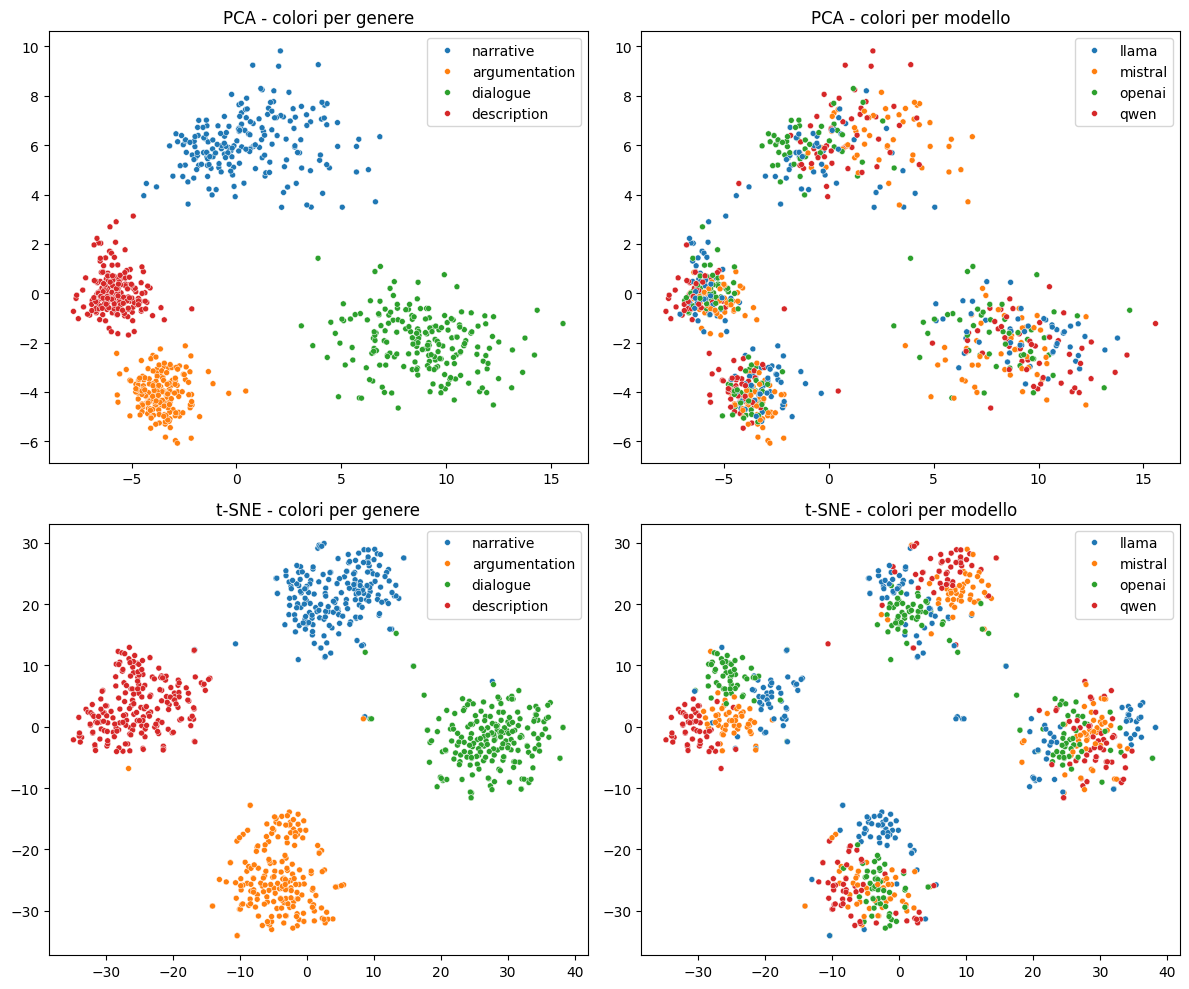

In [10]:
fig, assi = plt.subplots(2, 2, figsize=(12, 10))

for riga, (coord, nome) in enumerate([(X_pca, 'PCA'), (X_tsne, 't-SNE')]):
    sns.scatterplot(x=coord[:, 0], y=coord[:, 1], hue=y_topic, s=18, ax=assi[riga, 0])
    assi[riga, 0].set_title(nome + ' - colori per genere')
    sns.scatterplot(x=coord[:, 0], y=coord[:, 1], hue=y_modello, s=18, ax=assi[riga, 1])
    assi[riga, 1].set_title(nome + ' - colori per modello')

plt.tight_layout()
plt.show()

## UMAP



In [11]:
# UMAP: riduce a 2 dimensioni tenendo vicini i testi con feature simili
# n_neighbors piccolo = guarda la struttura locale, grande = quella globale
# (la variabile si chiama reducer e non umap, altrimenti sovrascrive il modulo)
reducer = umap.UMAP(n_neighbors=15, min_dist=0.1, n_components=2, random_state=42)
X_umap = reducer.fit_transform(X)
X_umap.shape

(800, 2)

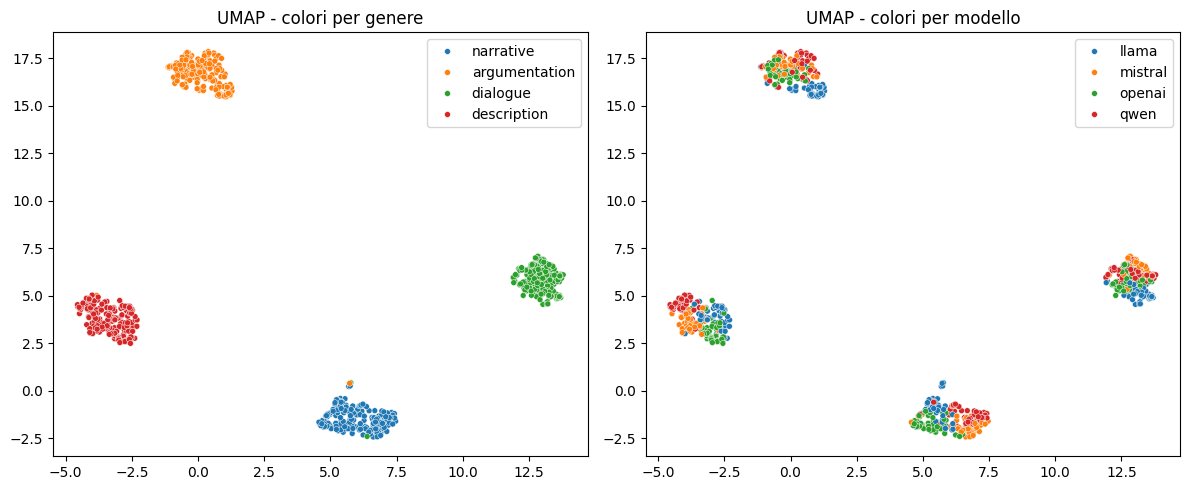

In [12]:
fig, assi = plt.subplots(1, 2, figsize=(12, 5))

sns.scatterplot(x=X_umap[:, 0], y=X_umap[:, 1], hue=y_topic, s=18, ax=assi[0])
assi[0].set_title('UMAP - colori per genere')
sns.scatterplot(x=X_umap[:, 0], y=X_umap[:, 1], hue=y_modello, s=18, ax=assi[1])
assi[1].set_title('UMAP - colori per modello')
plt.tight_layout()
plt.show()

> **What we see:** on the left the points group by genre, on the right the four models are mixed inside each group. The genre changes many features at the same time (for example dialogues have a very different punctuation and sentence structure from descriptions), so it dominates the variance, and PCA, t-SNE and UMAP show it first. The differences between models are smaller and are hidden inside each genre group.

## 4. K-Means and ARI

In [13]:
# K-Means con 4 cluster (4 generi = 4 modelli, quindi il numero va bene per entrambi)
# l'ARI vale 1 se i cluster coincidono con le etichette, 0 se sono casuali
spazi = {'feature complete': X, 'PCA 2D': X_pca, 't-SNE 2D': X_tsne, 'UMAP': X_umap}

righe = []
for nome, spazio in spazi.items():
    cluster = KMeans(n_clusters=4, n_init=10, random_state=42).fit_predict(spazio)
    righe.append({'spazio': nome,
                  'ARI vs genere': adjusted_rand_score(y_topic, cluster),
                  'ARI vs modello': adjusted_rand_score(y_modello, cluster)})

pd.DataFrame(righe).round(3)

,spazio,ARI vs genere,ARI vs modello
0,feature complete,0.987,-0.004
1,PCA 2D,0.980,-0.004
2,t-SNE 2D,0.970,-0.004
3,UMAP,0.983,-0.004


In [14]:
# stessa cosa dentro ogni genere: i cluster seguono i modelli?
for topic in sorted(set(y_topic)):
    maschera = (y_topic == topic)
    cluster = KMeans(n_clusters=4, n_init=10, random_state=42).fit_predict(X[maschera])
    print(topic, round(adjusted_rand_score(y_modello[maschera], cluster), 3))

argumentation 0.307
description 0.327
dialogue 0.394
narrative 0.407


In [15]:
# un esempio in un genere solo: come si dispongono i modelli?
topic = 'argumentation'            # prova anche 'argumentation', 'dialogue' o 'description'
maschera = (y_topic == topic)

# K-Means con 4 cluster solo sui testi di questo genere
cluster = KMeans(n_clusters=4, n_init=10, random_state=42).fit_predict(X[maschera])
print('ARI contro i modelli:', adjusted_rand_score(y_modello[maschera], cluster))

# quanti testi di ogni modello finiscono in ogni cluster
pd.crosstab(y_modello[maschera], cluster, rownames=['modello'], colnames=['cluster'])

ARI contro i modelli: 0.30691320324020327


cluster,0,1,2,3
modello,,,,
llama,2,1,45,2
mistral,8,1,1,40
openai,1,0,1,48
qwen,21,0,1,28


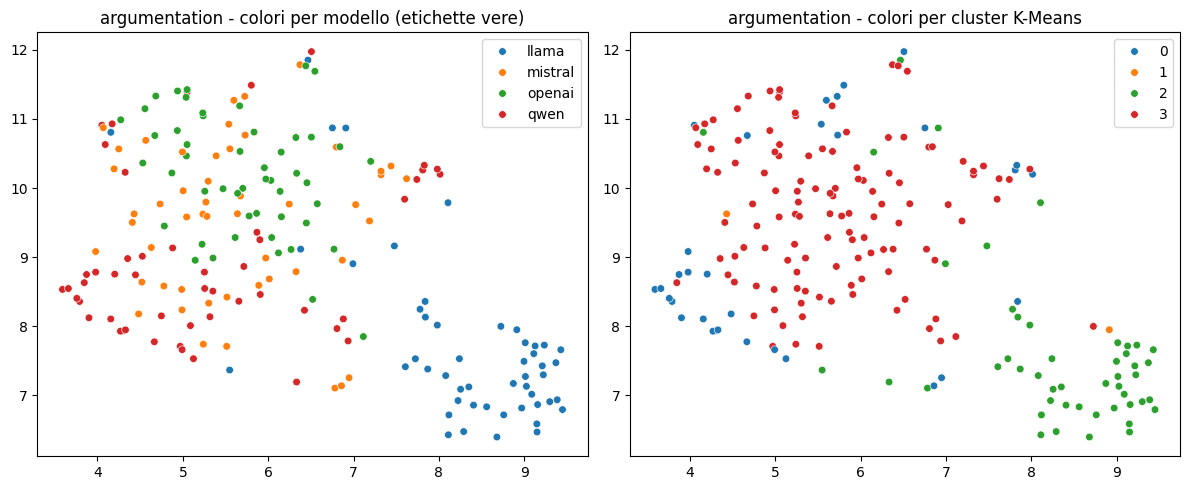

In [16]:
# riduco a 2 dimensioni solo i testi di questo genere (UMAP)
punti = umap.UMAP(n_neighbors=15, random_state=42).fit_transform(X[maschera])

fig, assi = plt.subplots(1, 2, figsize=(12, 5))

sns.scatterplot(x=punti[:, 0], y=punti[:, 1], hue=y_modello[maschera], s=30, ax=assi[0])
assi[0].set_title(topic + ' - colori per modello (etichette vere)')

sns.scatterplot(x=punti[:, 0], y=punti[:, 1], hue=cluster, palette='tab10', s=30, ax=assi[1])
assi[1].set_title(topic + ' - colori per cluster K-Means')

plt.tight_layout()
plt.show()

> **Comment:** the ARI with respect to the genre is very high (0.97-0.99 in all spaces) and with respect to the model it is about zero (-0.004): the clustering finds the dominant structure of the data, which is the genre. Inside a single genre the models emerge a little more (ARI between 0.31 and 0.41), but still only partially. So the stylistic fingerprint of the models is not the main source of variance, and an unsupervised method doesn't find it. The next step is a supervised classifier, which looks directly for the features that separate the models.

## 5. Random Forest

In [17]:
# test set: 10 prompt nuovi per genere, mai visti nel training
if os.path.exists('test_set_features.csv'):
    test_feat = pd.read_csv('test_set_features.csv')
else:
    test_feat = extract_stylometric_features(pd.read_csv('test_set.csv'))
    test_feat.to_csv('test_set_features.csv', index=False)

# stesse colonne e stesso scaler (calcolato solo sul training)
X_train, X_test, scaler, colonne = prepare_training_test_sets(feat, test_feat)
y_train = feat.modello.values
y_test = test_feat.modello.values
print(X_train.shape, X_test.shape)

(800, 163) (160, 163)


In [18]:
# cross-validation sul training: i fold sono divisi per prompt, cosi' lo stesso prompt
# non finisce sia nel train sia nella validazione
gruppi = (feat.topic + '_' + feat.prompt_id.astype(str)).values
print(gruppi)
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
rf = RandomForestClassifier(n_estimators=100, random_state=42)
punteggi = cross_val_score(rf, X_train, y_train, groups=gruppi, cv=cv)
print(f'{punteggi} | media: {punteggi.mean()}' )

<StringArray>
[   'narrative_0',    'narrative_0',    'narrative_0',    'narrative_0',
    'narrative_1',    'narrative_1',    'narrative_1',    'narrative_1',
    'narrative_2',    'narrative_2',
 ...
 'description_47', 'description_47', 'description_48', 'description_48',
 'description_48', 'description_48', 'description_49', 'description_49',
 'description_49', 'description_49']
Length: 800, dtype: str


[0.9     0.86875 0.91875 0.925   0.88125] | media: 0.8987499999999999


In [19]:
# alleno su tutto il training e provo sul test set
rf.fit(X_train, y_train)
y_pred = rf.predict(X_test)
print('accuratezza sul test set:', accuracy_score(y_test, y_pred))

accuratezza sul test set: 0.93125


In [20]:
# intervallo di confidenza al 95% (metodo di Wilson)
k, n = (y_pred == y_test).sum(), len(y_test)
p, z = k / n, 1.96
centro = (p + z**2 / (2 * n)) / (1 + z**2 / n)
meta = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
print(f'{k}/{n} corretti, intervallo 95%: {centro - meta:.3f} - {centro + meta:.3f}')

149/160 corretti, intervallo 95%: 0.881 - 0.961


In [21]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

       llama       0.95      0.97      0.96        40
     mistral       0.92      0.90      0.91        40
      openai       1.00      0.88      0.93        40
        qwen       0.87      0.97      0.92        40

    accuracy                           0.93       160
   macro avg       0.94      0.93      0.93       160
weighted avg       0.94      0.93      0.93       160



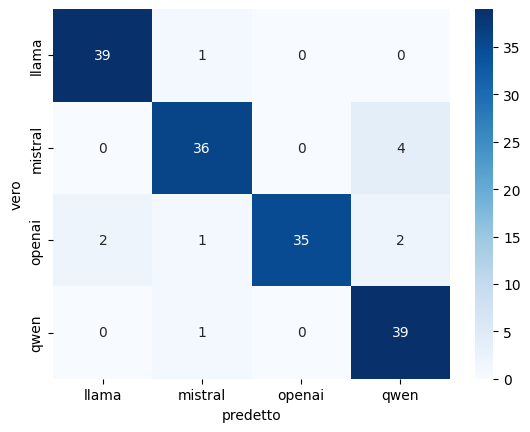

In [22]:
mat = confusion_matrix(y_test, y_pred, labels=rf.classes_)
sns.heatmap(mat, annot=True, fmt='d', cmap='Blues', xticklabels=rf.classes_, yticklabels=rf.classes_)
plt.xlabel('predetto')
plt.ylabel('vero')
plt.show()

In [23]:
# accuratezza sul test set, genere per genere
for topic in sorted(set(test_feat.topic)):
    m = (test_feat.topic == topic).values
    print(topic, round(accuracy_score(y_test[m], y_pred[m]), 3))

argumentation 0.925
description 0.875
dialogue 0.975
narrative 0.95


> **Results:** the chance level with 4 classes is 25%. The cross-validation gives 89.9% (the five folds go from 86.9% to 92.5%) and the test set 93.1% (149 texts out of 160), with a 95% confidence interval between 88.1% and 96.1%: far above chance, and the two estimates are consistent. The folds are split by prompt so that the same prompt never appears both in training and in validation: in this way the classifier cannot use the content of a prompt it has already seen, and the test set contains completely new prompts. By genre the accuracy goes from 87.5% (description) to 97.5% (dialogue). From the confusion matrix, the most frequent mistake is Mistral labelled as Qwen (4 texts), and Qwen is the model that receives the most wrong predictions; OpenAI is never predicted by mistake (precision 1.00), but some of its texts are labelled as other models.

### Which features separate the models the most

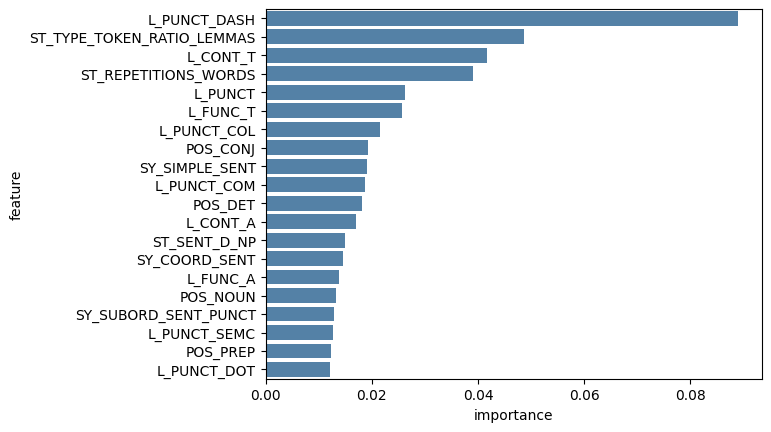

In [24]:
top10 = get_feature_importance(rf, colonne)
sns.barplot(data=top10, x='importance', y='feature', color='steelblue')
plt.show()

> **Comment:** the most important feature is the use of dashes (`L_PUNCT_DASH`), followed by the type-token ratio of the lemmas, the number of content words, the repetition of words and the overall punctuation; these are the "habits" that make up the fingerprint. The box plot of the dashes shows that Llama never uses them (the value is zero in all its texts), while Mistral and Qwen use them the most. The dashes alone are already useful: a Random Forest with only this feature reaches 46.9% on the test set (chance is 25%), but they are far from enough, because the full model reaches 93.1%. Note that this importance is the internal one of the Random Forest (decrease of impurity), which has some limits (for example it can favour features with many different values): permutation importance or SHAP would be a possible improvement.

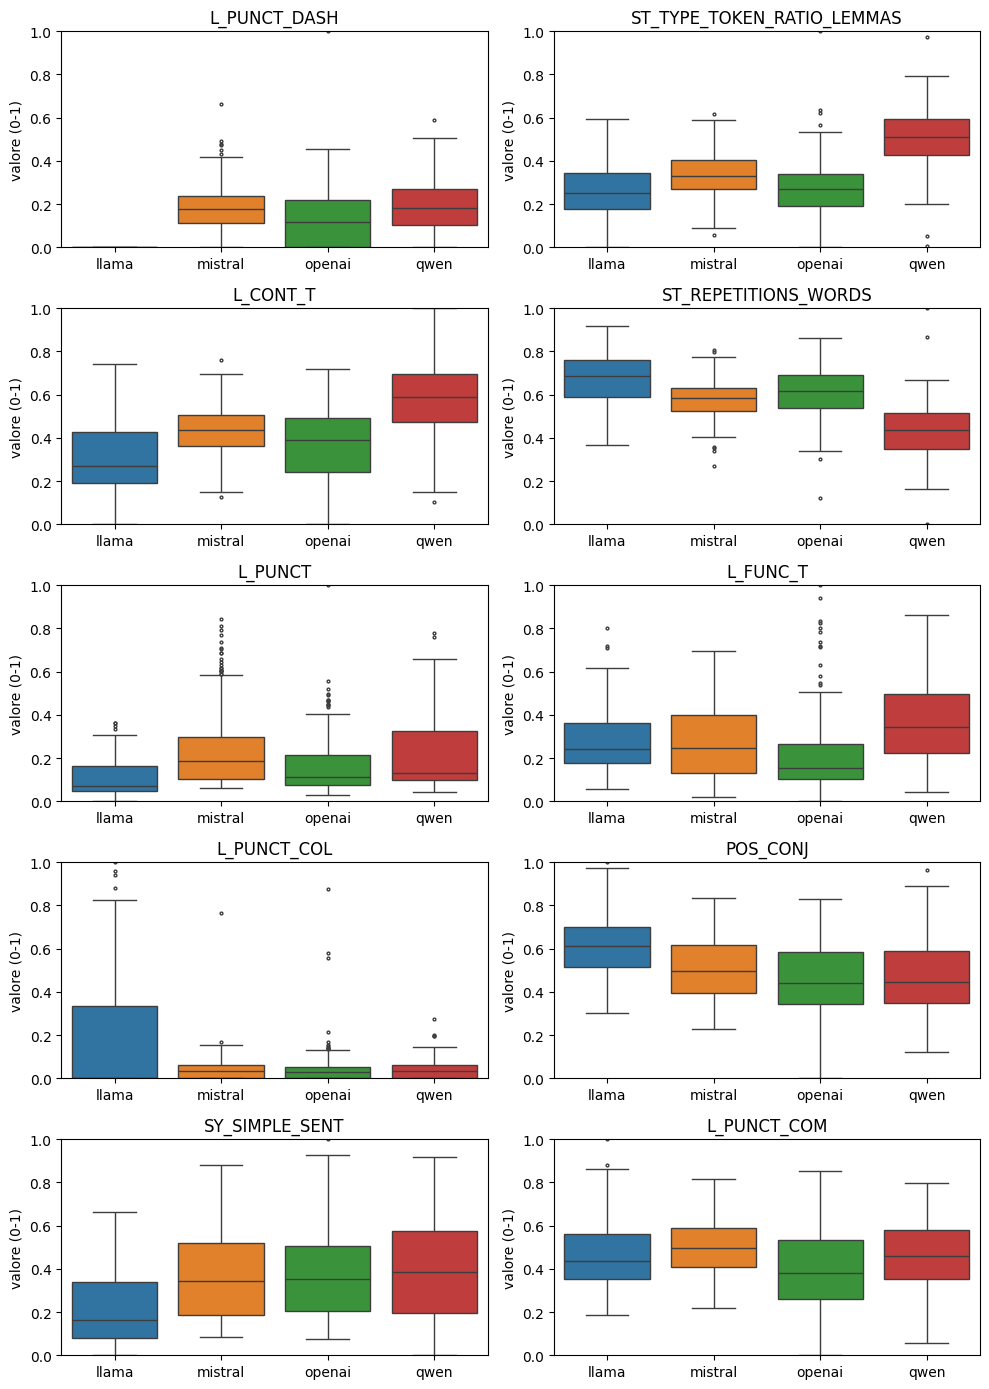

In [25]:
# come variano le prime 10 feature nei 4 modelli (box plot, tutte portate tra 0 e 1)
# riga nera = mediana, scatola = 50% centrale dei testi, baffi = il resto, punti = valori anomali
prime10 = top10['feature'].head(10).tolist()
ordine = ['llama', 'mistral', 'openai', 'qwen']

# porto ogni feature tra 0 e 1: 0 = valore piu' basso del dataset, 1 = il piu' alto
scalate = (feat[prime10] - feat[prime10].min()) / (feat[prime10].max() - feat[prime10].min())
scalate['modello'] = feat['modello'].values

fig, assi = plt.subplots(5, 2, figsize=(10, 14))

for ax, f in zip(assi.ravel(), prime10):
    sns.boxplot(data=scalate, x='modello', y=f, order=ordine, hue='modello', hue_order=ordine,
                fliersize=2, ax=ax)
    ax.set_ylim(0, 1)
    ax.set_yticks([0, 0.2, 0.4, 0.6, 0.8, 1])
    ax.set_title(f)
    ax.set_xlabel('')
    ax.set_ylabel('valore (0-1)')

plt.tight_layout()
plt.show()

## 6. Conclusions

The four LLMs leave a measurable stylistic fingerprint. It is not the dominant structure of the data, because the genre is: PCA, t-SNE, UMAP and K-Means group the texts by genre and not by model (ARI of 0.98 against 0). A supervised Random Forest, instead, recognises the model with about 90% accuracy in cross-validation (89.9%) and 93.1% on unseen prompts, using habits of punctuation, repetition and lexical variety. The two methods give different answers because they look for different things: clustering finds the largest variance, the classifier finds the features that separate the labels. The limits are the small number of models (4), a single language and feature extractor, the different length of the texts, and the lack of a human baseline. The robustness of the fingerprint is tested in the second notebook.